# Five-Step Allopatric/Vicariance Scenario Test

A richer five-step synthetic scenario using the previous slide-derived steps 1 and 2, followed by three more complicated river-evolution steps. The notebook plots zone IDs, fish species IDs, transition tables, event tables, and a calculated species tree.

In [37]:
import importlib
import sys
from pathlib import Path

repo_root = Path.cwd().resolve()
if (repo_root / "src").exists():
    sys.path.insert(0, str(repo_root / "src"))

import numpy as np
import matplotlib.pyplot as plt

import magratheamorph.lineage as _morph_lineage
import magratheamorph.visualization as _morph_visualization
importlib.reload(_morph_lineage)
importlib.reload(_morph_visualization)

from magratheamorph.model import SpeciationModel
from magratheamorph.readers import DemFrame
from magratheamorph.visualization import plot_parent_daughter_tree, plot_richness_map, plot_species_map, plot_zone_map
from magratheamorph.zones import ZoneExtractor, compute_zone_transitions, compute_biological_transitions


In [38]:
# Steps 1 and 2 are the previous slide-derived examples.
# Steps 3-5 are synthetic, more complicated continuations that test
# persistence, fragmentation, reconnection, extinction, secondary contact,
# and new-zone seeding.
STEP1 = np.array(
    [
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
    ], dtype=float)

STEP2 = np.array(
    [
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
    ], dtype=float)

# Complex continuation: more links form among the middle networks while one
# upper-left remnant disappears. A short-lived right-center island appears.
STEP3 = np.array(
    [
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0],
        [0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
    ], dtype=float)

# Fragmentation: central/right networks split into isolated pieces, while the
# far-right column disappears. This should generate extinctions and begin or
# continue allopatric isolation.
STEP4 = np.array(
    [
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
    ], dtype=float)

# Reconnection plus new habitats: some previously isolated pieces reconnect,
# creating secondary contact, and new far-right habitats appear and should get
# seeded species when seed_new_zones=True.
STEP5 = np.array(
    [
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0],
        [0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
        [0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0],
    ], dtype=float)

MASKS = [STEP1, STEP2, STEP3, STEP4, STEP5]


In [ ]:
def frame(time, masletk):
    return DemFrame(time=time, elevation=np.zeros_like(mask), x=np.arange(mask.shape[1]), y=np.arange(mask.shape[0]), drainage_area=mask)

extractor = ZoneExtractor(min_drainage_area=0.5, connectivity=8, use_catchments=False)
zone_maps = []
previous = None
for index, mask in enumerate(MASKS, start=1):
    zone_map = extractor.extract(frame(index, mask), previous=previous)
    zone_maps.append(zone_map)
    previous = zone_map

# Two time units of persistent isolation are required for speciation.
model = SpeciationModel(time_to_speciation=0, seed_new_zones=True)
model.initialize(zone_maps[0])
for zone_map in zone_maps[1:]:
    model.step(zone_map)

for zone_map in zone_maps:
    print(f"step {zone_map.time}: {len(zone_map.zones)} zones -> {sorted(zone_map.zones)}")
    
species_rows = sorted(model.species_table(), key=lambda row: row["species_id"])
event_rows = model.event_table()
end_time = max(zone_map.time for zone_map in zone_maps)

print("Parent -> daughter relationships")
for row in species_rows:
    if row["parent_id"] is not None:
        print(f'  species {row["parent_id"]} -> species {row["species_id"]} at time {row["origin_time"]}')


step 1: 12 zones -> [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
step 2: 10 zones -> [0, 1, 2, 4, 6, 7, 8, 9, 12, 13]
step 3: 8 zones -> [0, 2, 4, 6, 7, 8, 12, 13]
step 4: 10 zones -> [0, 2, 4, 6, 7, 8, 12, 13, 14, 15]
step 5: 11 zones -> [0, 2, 4, 6, 7, 8, 12, 13, 14, 15, 16]
Parent -> daughter relationships
  species 4 -> species 13 at time 2
  species 5 -> species 14 at time 4
  species 6 -> species 15 at time 4
  species 7 -> species 16 at time 4
  species 11 -> species 17 at time 4


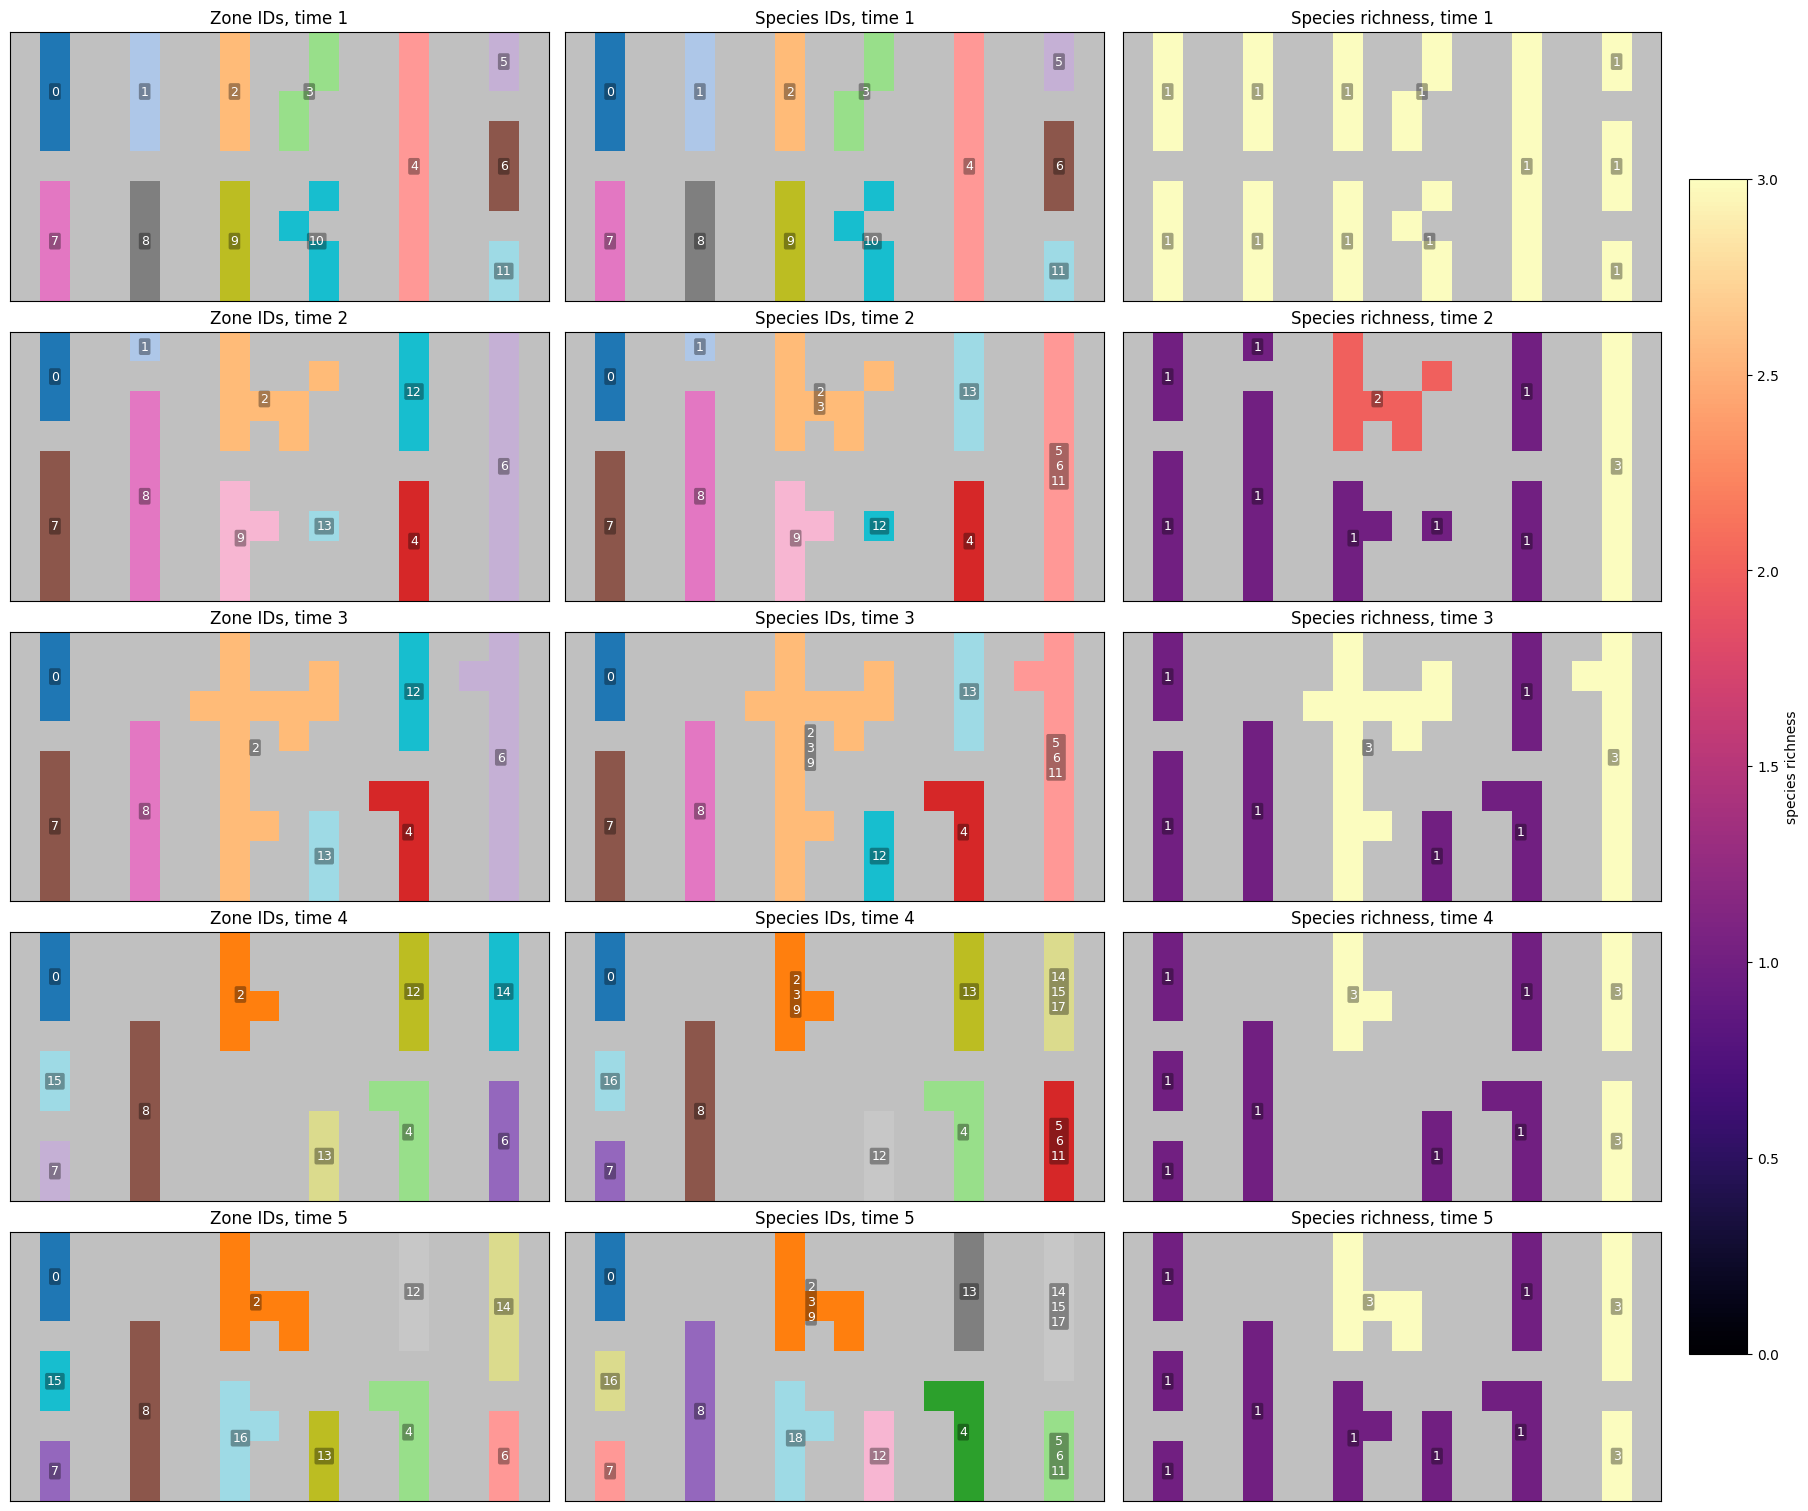

In [40]:
fig, axes = plt.subplots(len(zone_maps), 3, figsize=(18, 3 * len(zone_maps)), constrained_layout=True)
for row, zone_map in enumerate(zone_maps):
    plot_zone_map(axes[row, 0], zone_map)
    plot_species_map(axes[row, 1], model, zone_map, max_labels_per_zone=8)
    image = plot_richness_map(axes[row, 2], model, zone_map)
fig.colorbar(image, ax=axes[:, 2], label="species richness", shrink=0.8)
plt.show()


In [41]:
for before, after in zip(zone_maps[:-1], zone_maps[1:]):
    print(f"Step {before.time} -> {after.time}")
    print("  spatial overlaps:")
    for transition in compute_zone_transitions(before, after):
        print("   ", transition)
    print("  biological inheritance:")
    for transition in compute_biological_transitions(before, after):
        print("   ", transition)
    print()


Step 1 -> 2
  spatial overlaps:
    ZoneTransition(old_zone_id=0, new_zone_id=0, overlap_cells=3)
    ZoneTransition(old_zone_id=1, new_zone_id=8, overlap_cells=2)
    ZoneTransition(old_zone_id=1, new_zone_id=1, overlap_cells=1)
    ZoneTransition(old_zone_id=2, new_zone_id=2, overlap_cells=4)
    ZoneTransition(old_zone_id=3, new_zone_id=2, overlap_cells=3)
    ZoneTransition(old_zone_id=4, new_zone_id=4, overlap_cells=4)
    ZoneTransition(old_zone_id=4, new_zone_id=12, overlap_cells=4)
    ZoneTransition(old_zone_id=5, new_zone_id=6, overlap_cells=2)
    ZoneTransition(old_zone_id=6, new_zone_id=6, overlap_cells=3)
    ZoneTransition(old_zone_id=7, new_zone_id=7, overlap_cells=4)
    ZoneTransition(old_zone_id=8, new_zone_id=8, overlap_cells=4)
    ZoneTransition(old_zone_id=9, new_zone_id=9, overlap_cells=4)
    ZoneTransition(old_zone_id=11, new_zone_id=6, overlap_cells=2)
  biological inheritance:
    ZoneTransition(old_zone_id=0, new_zone_id=0, overlap_cells=3)
    ZoneTransiti

In [42]:
print("Events")
for event in model.event_table():
    if event["event_type"] != "species_origin":
        print(event)

print("Species table")
for row in model.species_table():
    print(row)

print("Final population table")
for row in model.population_table():
    print(row)


Events
{'time': 2, 'event_type': 'fragmentation', 'species_id': 4, 'old_zone_id': 4, 'new_zone_ids': [4, 12]}
{'time': 2, 'event_type': 'population_lost', 'population_id': 10, 'species_id': 10, 'old_zone_id': 10}
{'time': 2, 'event_type': 'new_zone_species', 'species_id': 12, 'zone_id': 13}
{'time': 2, 'event_type': 'speciation', 'parent_species_id': 4, 'daughter_species_ids': [13], 'isolation_parent': 4}
{'time': 2, 'event_type': 'extinction', 'species_id': 10}
{'time': 3, 'event_type': 'population_lost', 'population_id': 1, 'species_id': 1, 'old_zone_id': 1}
{'time': 3, 'event_type': 'extinction', 'species_id': 1}
{'time': 4, 'event_type': 'fragmentation', 'species_id': 5, 'old_zone_id': 6, 'new_zone_ids': [6, 14]}
{'time': 4, 'event_type': 'fragmentation', 'species_id': 6, 'old_zone_id': 6, 'new_zone_ids': [6, 14]}
{'time': 4, 'event_type': 'fragmentation', 'species_id': 7, 'old_zone_id': 7, 'new_zone_ids': [7, 15]}
{'time': 4, 'event_type': 'fragmentation', 'species_id': 11, 'old_z

In [43]:
species_rows = model.species_table()
parent_daughter = [
    (row["parent_id"], row["species_id"], row["origin_time"])
    for row in species_rows
    if row["parent_id"] is not None
]

print("Parent -> daughter relationships")
if parent_daughter:
    for parent_id, daughter_id, origin_time in parent_daughter:
        print(f"  species {parent_id} -> species {daughter_id} at time {origin_time}")
else:
    print("  no daughter species generated")


Parent -> daughter relationships
  species 4 -> species 13 at time 2
  species 5 -> species 14 at time 4
  species 6 -> species 15 at time 4
  species 7 -> species 16 at time 4
  species 11 -> species 17 at time 4


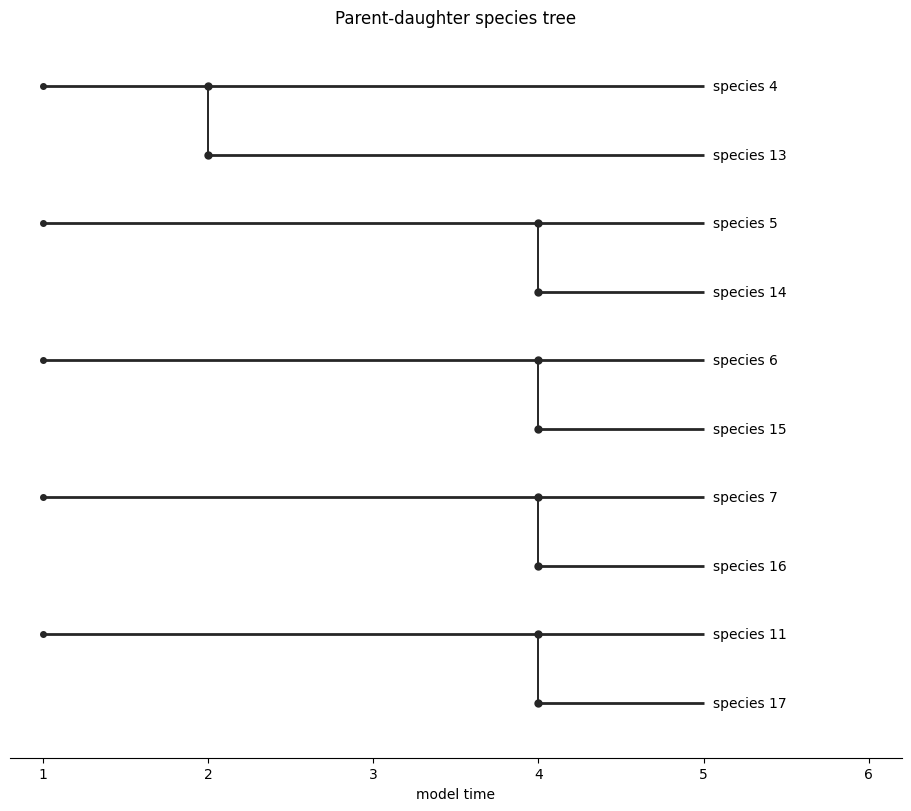

In [44]:
height = max(3.2, min(6.0, 0.055 * max(1, len(species_rows)) + 2.8))
fig, ax = plt.subplots(figsize=(10, height), constrained_layout=True)
plot_parent_daughter_tree(
    ax,
    species_rows,
    end_time=max(zone_map.time for zone_map in zone_maps),
    label_mode="all",
    max_labeled_species=10000,
    style="rectangular",
    time_unit="year",
    label_position="end",
    label_fontsize=6.5,
    time_block_cmap="Greens",
    time_block_count=5,
    show_time_blocks=True,
)
plt.show()


Expected behaviors to check visually:

- Steps 1 and 2 are the previous slide-derived zone examples.
- Steps 3-5 are more complex continuations with growth, shrinkage, splitting, reconnection, and habitat loss.
- Species IDs are model results, not copied from the masks.
- `time_to_speciation=1`, so one persistent interval is enough to generate a daughter species in this synthetic test.
- New zones receive new species because `seed_new_zones=True`.
- The final tree diagram shows parent-daughter relationships generated by allopatric/vicariance speciation.
